# Set-up

## Imports

In [79]:
import os
import random
import glob
from typing import Tuple, List, Dict, Any
import cv2
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

try:
    from torch.amp import GradScaler, autocast
    AMP_AVAILABLE = True
except ImportError:
    AMP_AVAILABLE = False
    class autocast:
        def __init__(self, enabled=False, **kwargs): self.enabled = enabled
        def __enter__(self): pass
        def __exit__(self, exc_type, exc_val, exc_tb): pass
    class GradScaler:
        def __init__(self, enabled=False): self.enabled = enabled
        def scale(self, loss): return loss
        def step(self, optimizer): optimizer.step()
        def update(self): pass

import numpy as np
from PIL import Image
from tqdm import tqdm
import imagehash
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import segmentation_models_pytorch as smp
from segmentation_models_pytorch.losses import TverskyLoss
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
import seaborn as sns

## Reproducibility

In [80]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## Configuration

In [81]:
def get_config() -> Dict[str, Any]:
    base_path = "../../"
    config = {
        "DEVICE": torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
        "RANDOM_SEED": 42, "NUM_WORKERS_TRAIN": 0, "NUM_WORKERS_VAL": 0, "USE_AMP": True,
        
        "DATASET_PATH_TRAIN": os.path.join(base_path, "dataset/training/train"),
        "DATASET_PATH_AUG": os.path.join(base_path, "dataset/training/augmented"),
        "DATASET_PATH_AUG_AGGR": os.path.join(base_path, "dataset/training/augmented_aggressive"),
        "MODEL_SAVE_PATH": os.path.join(base_path, "best_model_b5_aggressive_aug.pth"),

        "ENCODER": "efficientnet-b5", "ENCODER_WEIGHTS": "imagenet",
        "OUTPUT_SIZE": (384, 768), "BATCH_SIZE": 2, 
        "NUM_CLASSES": 9, "IGNORE_INDEX": 0, "VALIDATION_SPLIT": 0.2,

        "FREEZE_EPOCHS": 7, "UNFREEZE_EPOCHS": 23,
        "LR_HEAD": 1e-3, "LR_FULL": 1e-5, "WEIGHT_DECAY": 1e-5,
    }
    
    # FIX: Nomi delle classi anonimi come da richiesta
    config["CLASS_NAMES"] = ["Ignored"] + [f"Classe {i}" for i in range(1, config["NUM_CLASSES"])]

    # --- CALCOLO CORRETTO DI MEDIA E DEVIAZIONE STANDARD ---
    tqdm.write("Preparazione per il calcolo delle statistiche del dataset...")
    
    # 1. Pipeline di trasformazione SENZA A.Normalize
    stats_transforms = A.Compose([
        A.Resize(height=config["OUTPUT_SIZE"][0], width=config["OUTPUT_SIZE"][1]),
        # ToTensorV2 è fondamentale perché scala le immagini da [0, 255] a [0, 1]
        A.Normalize(mean=(0.0, 0.0, 0.0), std=(1.0, 1.0, 1.0), max_pixel_value=255.0),
        ToTensorV2(),
    ])

    # 2. Crea un Dataset temporaneo usando solo i dati originali
    train_original_dirs = [d for d in glob.glob(os.path.join(config["DATASET_PATH_TRAIN"], "*")) if os.path.isdir(d)]
    stats_dataset = SegmentationDataset(
        sample_dirs=train_original_dirs,
        transform=stats_transforms,
        config=config  # Passa la config per l'assert nel dataset
    )

    # 3. Avvolgi il Dataset in un DataLoader (IL FIX FONDAMENTALE)
    stats_loader = DataLoader(
        stats_dataset, 
        batch_size=config["BATCH_SIZE"] * 2, # Possiamo usare un batch size più grande qui
        shuffle=False, 
        num_workers=config["NUM_WORKERS_TRAIN"]
    )
    
    # 4. Ora chiama la funzione con il DataLoader
    mean, std = calculate_mean_std(stats_loader)

    assert 0.0 <= mean.min() and mean.max() <= 1.0,  "Mean fuori range 0-1"
    assert 0.0 <  std.min()  and std.max()  <  1.0,  "Std anomala"
    
    # 5. Salva i valori calcolati nella configurazione
    config["MEAN"] = mean
    config["STD"] = std

    tqdm.write("Statistiche personalizzate calcolate e caricate nella configurazione.")
    return config

## Mean & Std

In [82]:
def calculate_mean_std(loader: DataLoader) -> Tuple[np.ndarray, np.ndarray]:
    """
    Calcola la media e la deviazione standard per canale su un intero dataset.
    È numericamente stabile.
    """
    tqdm.write("Calcolo di media e deviazione standard in corso...")
    
    psum = torch.tensor([0.0, 0.0, 0.0])
    psum_sq = torch.tensor([0.0, 0.0, 0.0])
    pixel_count = 0

    for images, _ in tqdm(loader, desc="Analisi Statistiche Dataset"):
        batch_size, num_channels, height, width = images.shape
        psum += images.sum(axis=[0, 2, 3])
        psum_sq += (images ** 2).sum(axis=[0, 2, 3])
        pixel_count += batch_size * height * width

    total_mean = psum / pixel_count
    total_var = (psum_sq / pixel_count) - (total_mean ** 2)
    
    # --- FIX PER LA STABILITÀ NUMERICA ---
    # Assicura che la varianza non sia mai negativa a causa di errori di precisione.
    # Usiamo un minimo piccolo e positivo per evitare anche sqrt(0).
    total_std = torch.sqrt(torch.clamp(total_var, min=1e-6))

    mean_np = total_mean.numpy()
    std_np = total_std.numpy()

    tqdm.write("\n--- Statistiche Dataset Calcolate ---")
    tqdm.write(f"Media per canale (R, G, B): {mean_np}")
    tqdm.write(f"Deviazione Standard per canale (R, G, B): {std_np}")
    
    return mean_np, std_np

# Segmentation Dataset

In [83]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset
from typing import List, Tuple, Dict, Any
import albumentations as A

class SegmentationDataset(Dataset):
    def __init__(self, sample_dirs: List[str], transform: A.Compose, config: Dict[str, Any]):
        self.sample_dirs, self.transform, self.config = sample_dirs, transform, config

    def __len__(self) -> int: return len(self.sample_dirs)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        sample_dir = self.sample_dirs[idx]
        
        image = np.array(Image.open(os.path.join(sample_dir, 'rgb.jpg')).convert("RGB"))
        mask = np.array(Image.open(os.path.join(sample_dir, 'labels.png')))

        assert mask.dtype == np.uint8, f"Tipo maschera non corretto: {mask.dtype}"
        assert mask.max() < self.config["NUM_CLASSES"], f"ID classe non valido in {os.path.join(sample_dir, 'labels.png')}"

        augmented = {'image': image, 'mask': mask}
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)

        return augmented['image'], augmented['mask']

In [84]:
config = get_config()
device = config["DEVICE"]

Preparazione per il calcolo delle statistiche del dataset...
Calcolo di media e deviazione standard in corso...


Analisi Statistiche Dataset: 100%|██████████| 233/233 [00:11<00:00, 19.61it/s]


--- Statistiche Dataset Calcolate ---
Media per canale (R, G, B): [0.42948496 0.44826746 0.42454118]
Deviazione Standard per canale (R, G, B): [0.2645671  0.26363927 0.26595324]
Statistiche personalizzate calcolate e caricate nella configurazione.


# Splitting Function

In [85]:
import glob
from torch.utils.data import random_split
from typing import Tuple


def split_dataset(data_dir, batch_size) -> Tuple[DataLoader, DataLoader]:
  """
  Funzione per dividere il dataset in training e validation set.
  """

  # 1. Trova tutte le directory dei campioni
  all_sample_dirs = sorted(glob.glob(os.path.join(data_dir, "*")))
  print(f"Trovati {len(all_sample_dirs)} campioni totali.")

  # 2. Dividi le directory in training e validation set
  # Definiamo la dimensione del set di validazione (20%)
  val_percent = 0.20
  n_val = int(len(all_sample_dirs) * val_percent)
  n_train = len(all_sample_dirs) - n_val

  # Usiamo random_split per creare due sotto-liste di percorsi
  # impostiamo un generator per la riproducibilità dello split
  generator = torch.Generator().manual_seed(42)
  train_dirs, val_dirs = random_split(all_sample_dirs, [n_train, n_val], generator=generator)

  print(f"Numero di campioni per training: {len(train_dirs)}")
  print(f"Numero di campioni per validazione: {len(val_dirs)}")

  # 3. Creiamo le istanze dei due Dataset
  train_dataset = SegmentationDataset(sample_dirs=list(train_dirs), transform=None, config=config)
  val_dataset = SegmentationDataset(sample_dirs=list(val_dirs), transform=None, config=config)

  # 4. Creiamo i DataLoader
  # Il DataLoader si occuperà di creare i batch e mescolare i dati
  train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=config["NUM_WORKERS_TRAIN"])
  val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=config["NUM_WORKERS_VAL"])
  return train_loader, val_loader



train_loader, val_loader = split_dataset(config["DATASET_PATH_TRAIN"], config["BATCH_SIZE"])

Trovati 931 campioni totali.
Numero di campioni per training: 745
Numero di campioni per validazione: 186


Forma del batch di immagini: torch.Size([2, 544, 1024, 3])
Forma del batch di maschere: torch.Size([2, 544, 1024])


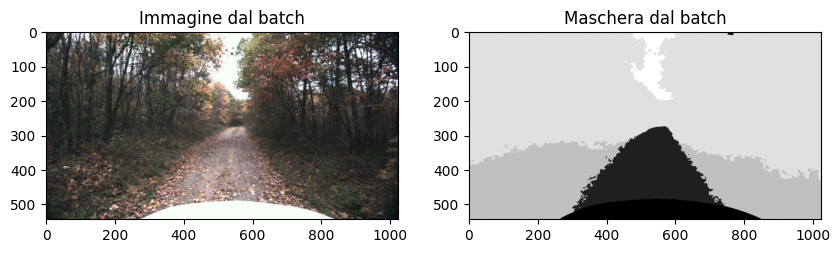

In [86]:
# --- ESEMPIO DI UTILIZZO ---

def segmentationDataset_test(train_loader):
  # Prendiamo un batch dal train_loader per vedere come funziona
  images_batch, masks_batch = next(iter(train_loader))

  print(f"Forma del batch di immagini: {images_batch.shape}") # Dovrebbe essere [batch_size, 3, H, W]
  print(f"Forma del batch di maschere: {masks_batch.shape}") # Dovrebbe essere [batch_size, 1, H, W]

  # Visualizziamo la prima immagine e maschera del batch
  plt.figure(figsize=(10, 5))
  plt.subplot(1, 2, 1)
  plt.imshow(images_batch[0]) # Rimetto in formato H, W, C
  plt.title("Immagine dal batch")

  plt.subplot(1, 2, 2)
  plt.imshow(masks_batch[0].squeeze(), cmap='gray')
  plt.title("Maschera dal batch")
  plt.show()




segmentationDataset_test(train_loader)

# Dataset distribuition



Trovati 931 campioni totali validi.


Analisi distribuzione classi (GPU):   0%|          | 0/15 [00:00<?, ?it/s]

Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:07<00:00,  2.03it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


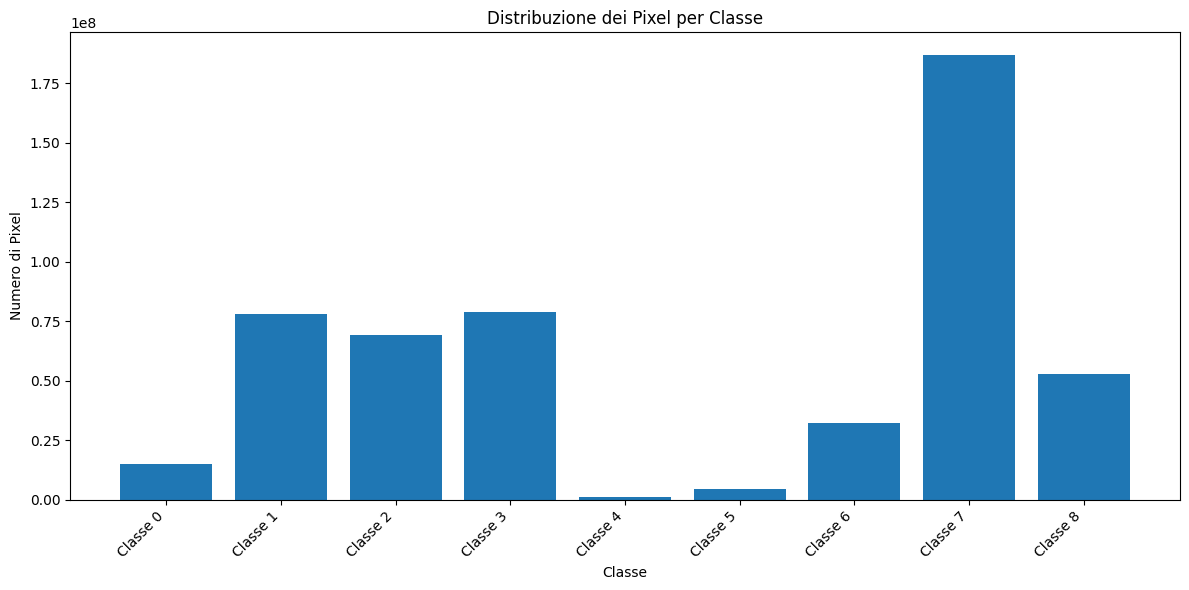

In [87]:
def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  """
  num_classes = 9 # Da 0 a 8

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=config["NUM_WORKERS_TRAIN"])

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      class_counts += torch.bincount(mask.flatten(), minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()


def distribution_analysis(full_dataset, class_names):
  # Calcoliamo la distribuzione
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # Stampiamo e visualizziamo i risultati
  total_pixels = distribution.sum()
  print("\nDistribuzione delle classi nel dataset:")
  for i, count in enumerate(distribution):
    percentage = 100 * count.float() / total_pixels
    print(f"- Classe '{class_names[i]}' ({i}): {count} pixel ({percentage:.2f}%)")

  plt.figure(figsize=(12, 6))
  plt.bar(class_names, distribution.numpy())
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()



# Creiamo un dataset con tutti i campioni ...
all_sample_dirs = sorted([d for d in glob.glob(os.path.join(config["DATASET_PATH_TRAIN"], "*")) if os.path.isdir(d)])
# ... senza __MACOSX
all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs, transform=None, config=config)

class_names = []
for idx in range(9):
  class_names.append(f"Classe {idx}")

distribution_analysis(full_dataset, class_names)

## Conclusions


The classes **are imbalanced**. Class 7 represents **36%** of the data, which is an extremely high value.

This situation is **problematic** because countermeasures must be implemented to encourage the model to bridge this gap and achieve more uniform learning. Otherwise, there is a *risk that the network will completely ignore the other classes and only learn the predominant one*.

To ensure a better learning process, we can use data augmentation and search for a loss function that minimizes cross-entropy loss while also mitigating the existing class imbalance.

The analysis of the data distribution suggests that we should not rely solely on accuracy. Instead, it is better to use the *mean Intersection-over-Union* (mIoU), which was the metric used in the contest. This metric allows us to understand how many pixels the network correctly identifies, both overall and on a per-class basis. This also enables us to evaluate and rank the performance of different loss functions.


# Co Occurrence Matrix

Analisi Co-occorrenza: 100%|██████████| 931/931 [00:11<00:00, 79.42it/s]


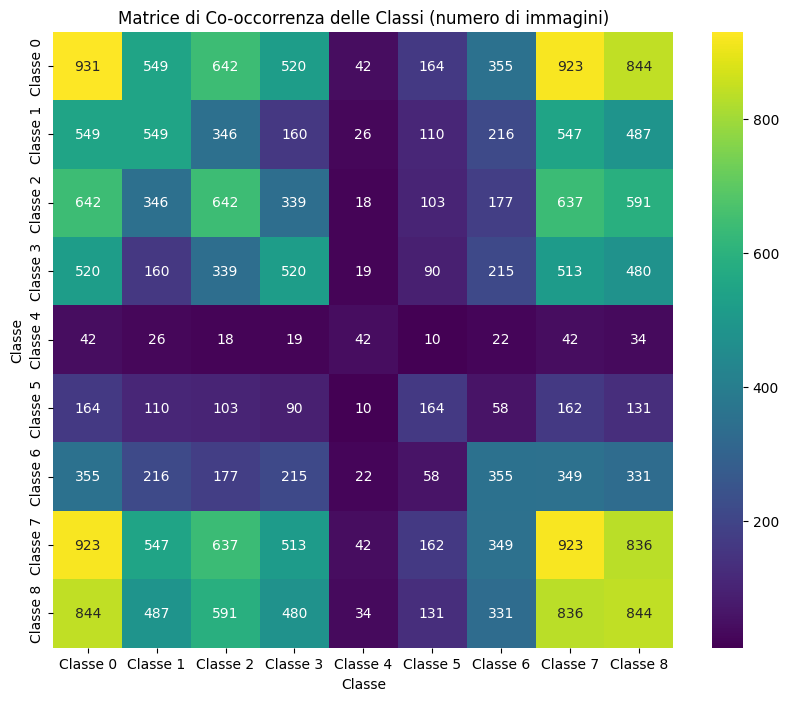

In [93]:
import itertools

def calculate_co_occurrence(dataset, num_classes):
    co_occurrence_matrix = torch.zeros((num_classes, num_classes), dtype=torch.int64)

    for _, mask in tqdm(dataset, desc="Analisi Co-occorrenza"):
        # 1. Get unique classes for the current mask
        unique_classes_in_mask = torch.unique(torch.from_numpy(mask))

        # 2. Generate all unique pairs of classes present in this mask
        # combinations_with_replacement handles pairs like (a,a) and (a,b)
        for class1, class2 in itertools.combinations_with_replacement(unique_classes_in_mask, 2):
            # Convert tensor to int for indexing
            c1 = class1.item()
            c2 = class2.item()
            
            # 3. Increment the count for the pair
            co_occurrence_matrix[c1, c2] += 1
            # If not on the diagonal, increment the symmetric position too
            if c1 != c2:
                co_occurrence_matrix[c2, c1] += 1

    return co_occurrence_matrix

def co_occurance_analysis(full_dataset, class_names):
  # Calcoliamo la matrice sul dataset completo con la versione corretta
  co_occurrence_matrix = calculate_co_occurrence(full_dataset, num_classes=9)

  # Visualizziamo con una heatmap per una migliore leggibilità
  plt.figure(figsize=(10, 8))
  sns.heatmap(co_occurrence_matrix.numpy(), annot=True, fmt='d', cmap='viridis',
              xticklabels=class_names, yticklabels=class_names)
  plt.title("Matrice di Co-occorrenza delle Classi (numero di immagini)")
  plt.xlabel("Classe")
  plt.ylabel("Classe")
  plt.show()

# Re-run the analysis
co_occurance_analysis(full_dataset, class_names)

# Pixels & Classes

In [96]:
import torch
from tqdm import tqdm
import os
import itertools # We can reuse this from the previous fix if needed, but not required here.

def get_representative_images_per_class(dataset, num_classes, class_names, top_n=5):
    """
    Analizza il dataset per trovare le 'top_n' immagini più rappresentative per ogni classe.

    Args:
        dataset (Dataset): L'istanza del dataset completo.
        num_classes (int): Il numero di classi totali.
        class_names (list): La lista dei nomi delle classi.
        top_n (int): Il numero di immagini da mostrare per ogni classe.
    """
    print(f"Inizio analisi per trovare le {top_n} immagini più rappresentative per classe...")

    # Questa struttura dati è perfetta per lo scopo
    class_images = [[] for _ in range(num_classes)]

    for i in tqdm(range(len(dataset)), desc="Analisi Immagini"):
        # dataset[i] restituisce (immagine_numpy, maschera_numpy)
        _, numpy_mask = dataset[i]

        # FIX: Convertire la maschera da NumPy array a PyTorch Tensor
        mask = torch.from_numpy(numpy_mask)

        # Ora il codice seguente funzionerà correttamente
        total_pixels_in_mask = mask.numel()
        if total_pixels_in_mask == 0:
            continue
        
        counts = torch.bincount(mask.flatten(), minlength=num_classes)

        for class_id in range(num_classes):
            if counts[class_id] > 0:
                # La metrica di 'rappresentatività' è la percentuale di copertura
                percentage = 100.0 * counts[class_id] / total_pixels_in_mask
                sample_path = dataset.sample_dirs[i]
                class_images[class_id].append((percentage, sample_path))

    print("\nAnalisi completata. Ordino e stampo i risultati...")

    # Ordinamento e Stampa (questa parte era già corretta)
    for class_id in range(num_classes):
        print("-" * 50)
        print(f"CLASSE: {class_names[class_id].upper()} ({class_id})")
        print("-" * 50)

        # Ordina le immagini per percentuale di copertura, in ordine decrescente
        sorted_images = sorted(class_images[class_id], key=lambda x: x[0], reverse=True)

        if not sorted_images:
            print("Nessuna immagine trovata per questa classe.")
            continue

        # Stampa solo i primi 'top_n' elementi
        for idx, (percentage, path) in enumerate(sorted_images[:top_n]):
            print(f"{idx + 1}. {os.path.basename(path)} (presenza: {percentage:.2f}%)")

# --- ESECUZIONE DELLA FUNZIONE CORRETTA ---
print("--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---")
get_representative_images_per_class(full_dataset, num_classes=9, class_names=class_names, top_n=1)

--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---
Inizio analisi per trovare le 1 immagini più rappresentative per classe...


Analisi Immagini: 100%|██████████| 931/931 [00:07<00:00, 121.59it/s]



Analisi completata. Ordino e stampo i risultati...
--------------------------------------------------
CLASSE: CLASSE 0 (0)
--------------------------------------------------
1. 0546 (presenza: 44.05%)
--------------------------------------------------
CLASSE: CLASSE 1 (1)
--------------------------------------------------
1. 0312 (presenza: 66.15%)
--------------------------------------------------
CLASSE: CLASSE 2 (2)
--------------------------------------------------
1. 0833 (presenza: 73.56%)
--------------------------------------------------
CLASSE: CLASSE 3 (3)
--------------------------------------------------
1. 1147 (presenza: 66.82%)
--------------------------------------------------
CLASSE: CLASSE 4 (4)
--------------------------------------------------
1. 0305 (presenza: 19.65%)
--------------------------------------------------
CLASSE: CLASSE 5 (5)
--------------------------------------------------
1. 0531 (presenza: 39.47%)
------------------------------------------------

class 0


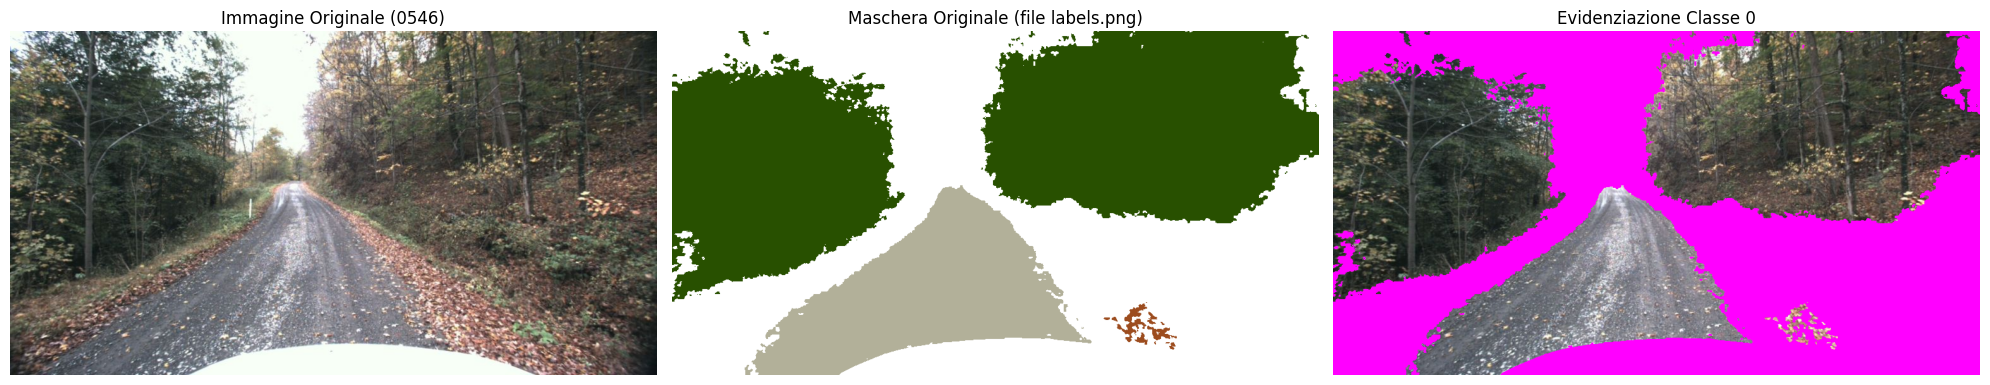

class 1


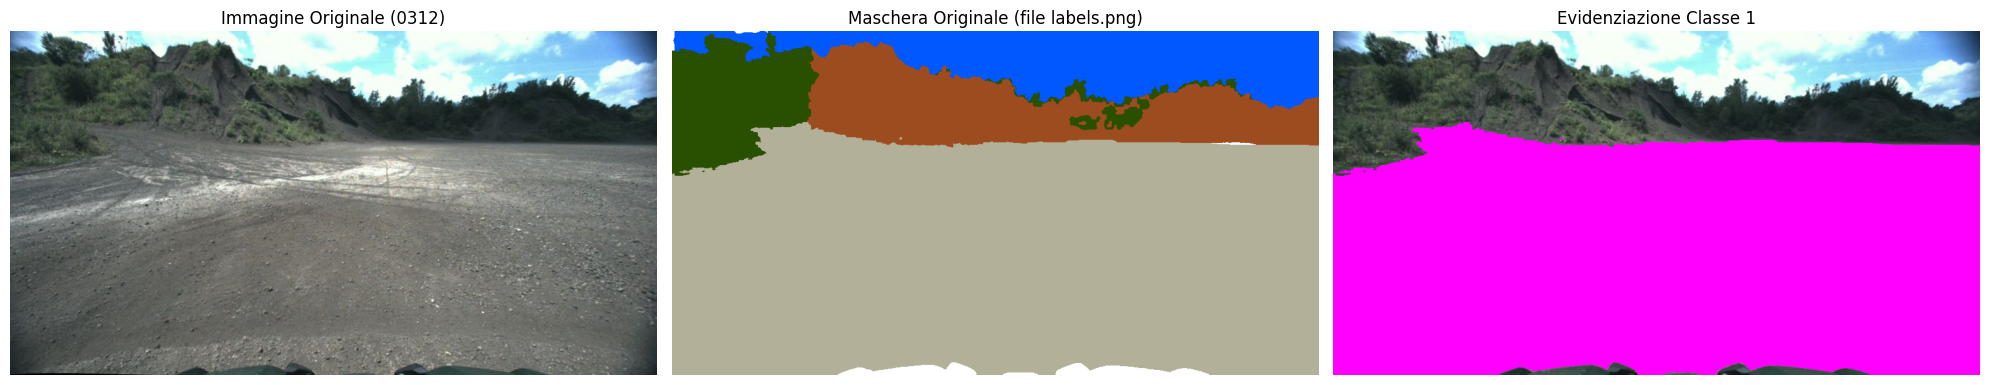

class 2


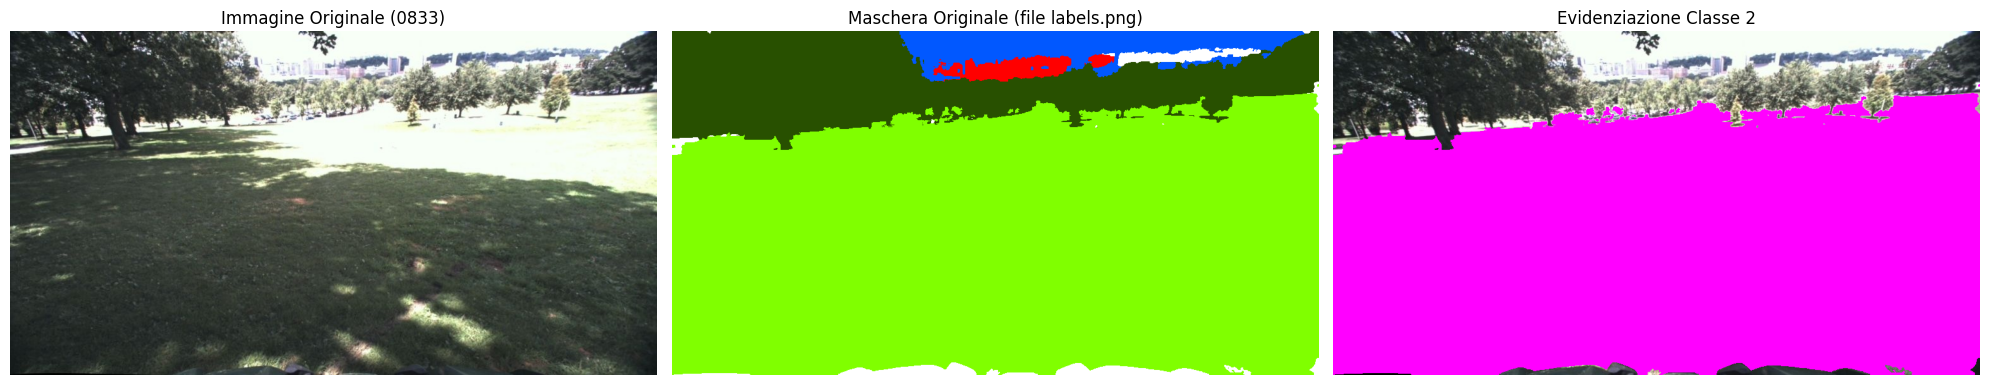

class 3


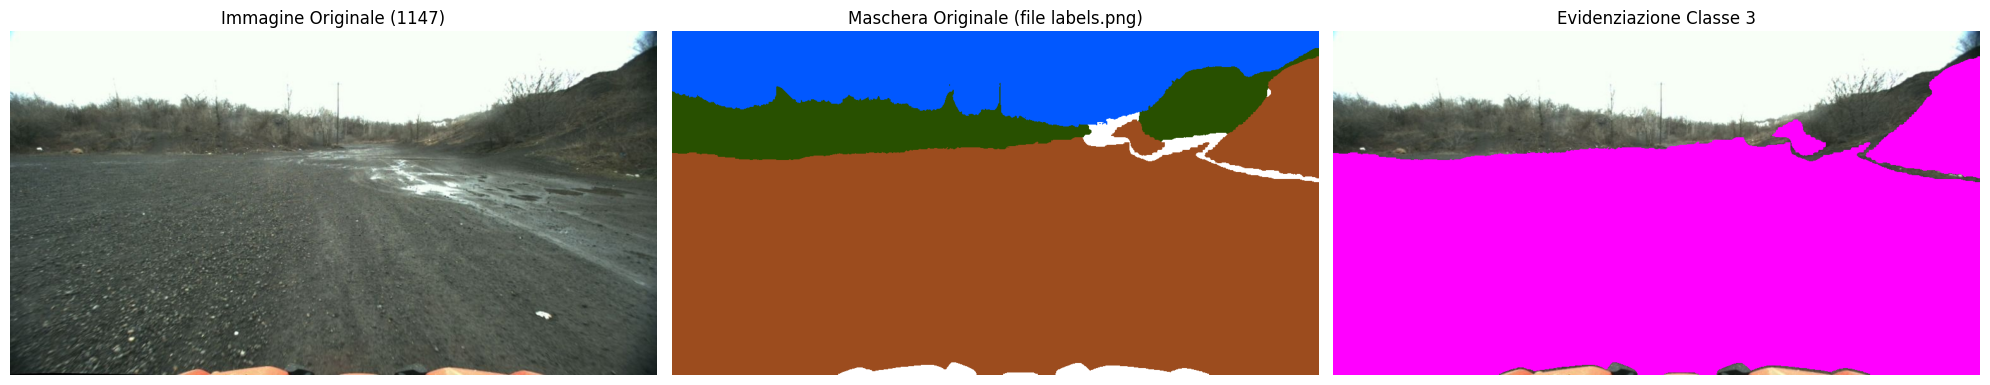

class 4


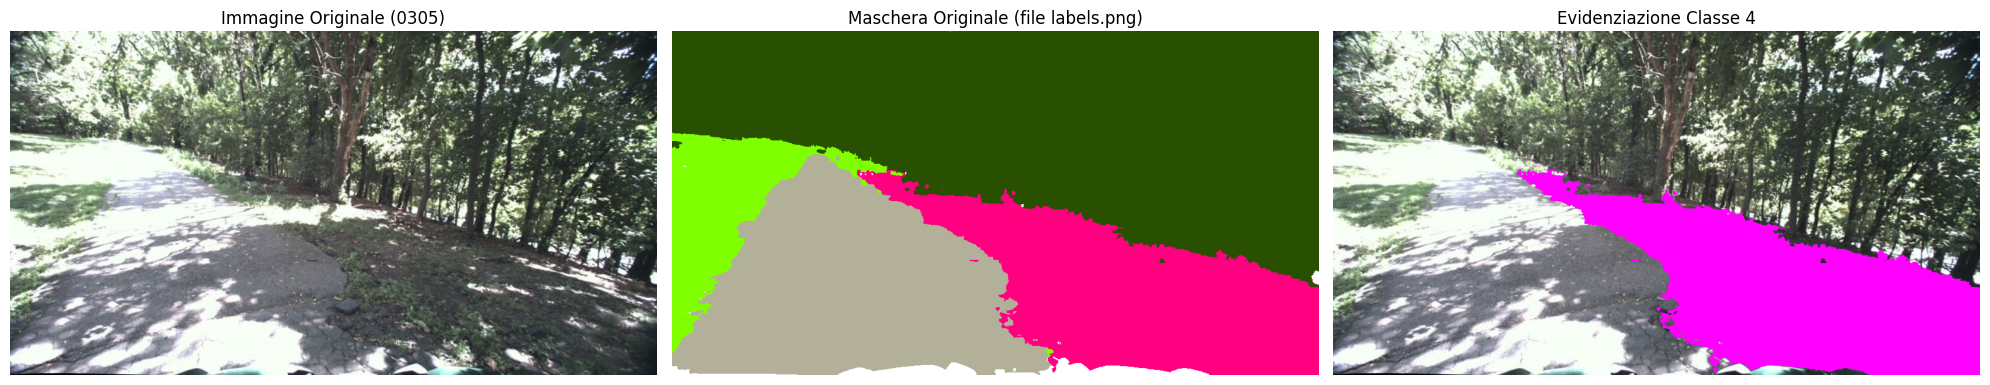

class 5


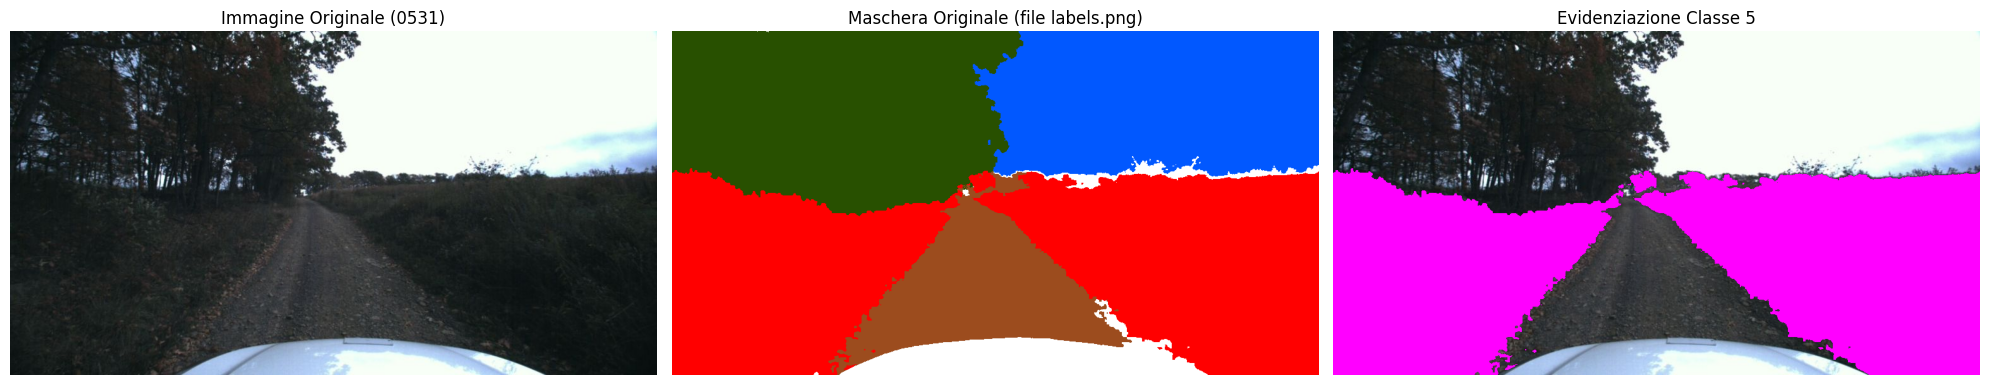

class 6


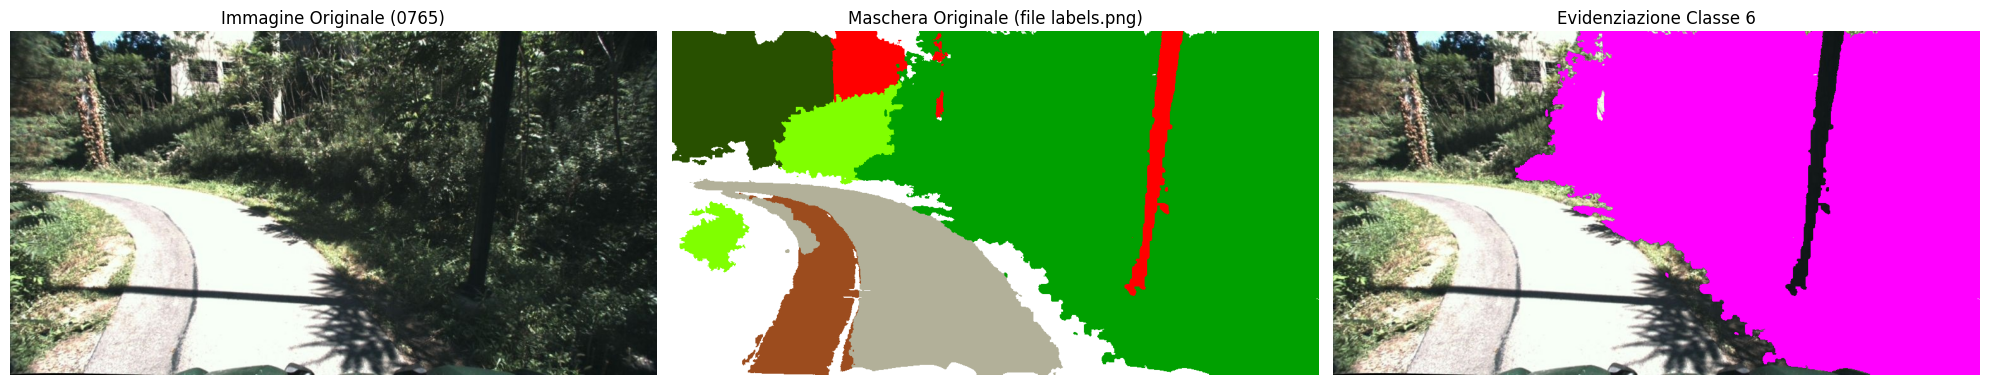

class 7


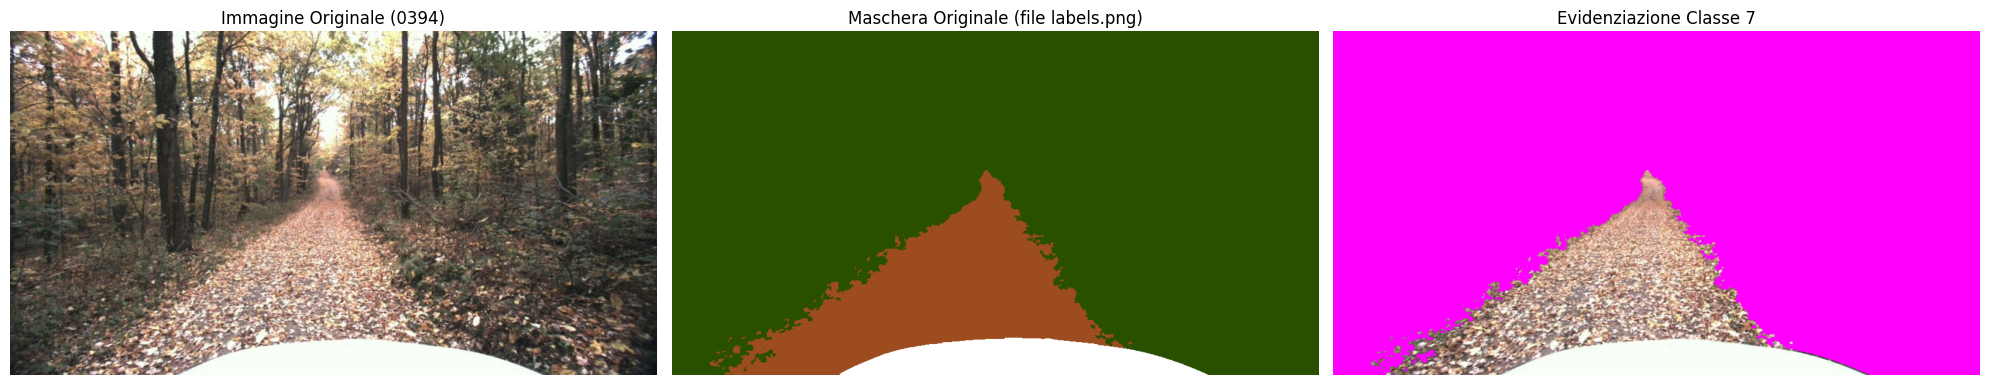

class 8


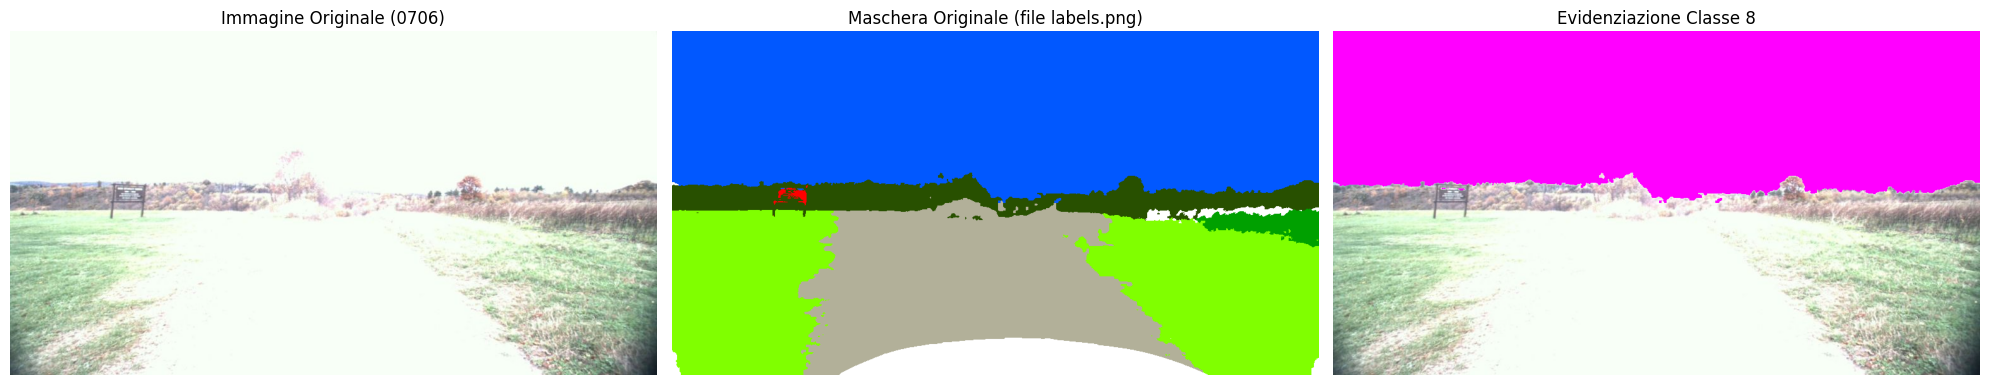

In [97]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os

def highlight_class_in_image_simple(sample_dir_path, class_id_to_highlight, highlight_color=[255, 0, 255]):
    """
    Carica un'immagine, la sua maschera originale (come file), e crea una versione
    evidenziata per una classe specifica.

    Args:
        sample_dir_path (string): Il percorso completo alla cartella del campione
        class_id_to_highlight (int): L'ID della classe da evidenziare.
        highlight_color (list): Il colore RGB per l'evidenziazione.
    """

    img_path = os.path.join(sample_dir_path, 'rgb.jpg')
    mask_path = os.path.join(sample_dir_path, 'labels.png')

    try:
        # Carica l'immagine originale e la maschera come file immagine
        original_image = Image.open(img_path)
        original_mask_image = Image.open(mask_path)

        # Crea l'immagine evidenziata
        # Per farlo, dobbiamo comunque leggere la maschera come array di indici
        mask_np = np.array(original_mask_image) # Questo legge gli indici (0-8)

        highlighted_image = np.array(original_image).copy()
        pixels_to_highlight = (mask_np == class_id_to_highlight)
        highlighted_image[pixels_to_highlight] = highlight_color

    except FileNotFoundError:
        print(f"Errore: file non trovati nel percorso {sample_dir_path}")
        return

    # Visualizza tutto
    sample_name = os.path.basename(sample_dir_path)

    plt.figure(figsize=(20, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(original_image)
    plt.title(f"Immagine Originale ({sample_name})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(original_mask_image)
    plt.title("Maschera Originale (file labels.png)")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(highlighted_image)
    plt.title(f"Evidenziazione Classe {class_id_to_highlight}")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# --- Esempio di utilizzo ---
# Passiamo direttamente il percorso della cartella, non l'indice.

# Percorso alla cartella del campione

images = ["0546","0312", "0833","1147","0305","0531","0765","0394", "0706"]

for idx, image in enumerate(images):
  print(f"class {idx}")
  path = os.path.join(config["DATASET_PATH_TRAIN"], image)
  highlight_class_in_image_simple(path, class_id_to_highlight=idx)


# Analisi Sul Bilanciamento

--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---

Processing Target: Classe 0


-> Analisi per Classe 0 completata. Trovata in 931 immagini.

Processing Target: Classe 1


-> Analisi per Classe 1 completata. Trovata in 549 immagini.

Processing Target: Classe 2


-> Analisi per Classe 2 completata. Trovata in 642 immagini.

Processing Target: Classe 3


-> Analisi per Classe 3 completata. Trovata in 520 immagini.

Processing Target: Classe 4


-> Analisi per Classe 4 completata. Trovata in 42 immagini.

Processing Target: Classe 5


-> Analisi per Classe 5 completata. Trovata in 164 immagini.

Processing Target: Classe 6


-> Analisi per Classe 6 completata. Trovata in 355 immagini.

Processing Target: Classe 7


-> Analisi per Classe 7 completata. Trovata in 923 immagini.

Processing Target: Classe 8


-> Analisi per Classe 8 completata. Trovata in 844 immagini.


--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---
Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.
             Classe 0  Classe 1  Classe 2  Classe 3  Classe 4  Classe 5  Classe 6  Classe 7  Classe 8
Contesto C0     2.86%    15.04%    13.36%    15.20%     0.18%     0.87%     6.24%    36.06%    10.19%
Contesto C1     2.94%    25.51%    10.84%     3.71%     0.21%     0.83%     6.61%    39.52%     9.82%
Contesto C2     2.42%    11.70%    19.38%    15.67%     0.14%     0.59%     3.30%    36.13%    10.68%
Contesto C3     3.09%     8.97%    11.69%    27.21%     0.09%     1.11%     6.42%    31.08%    10.34%
Contesto C4     4.15%    21.48%     5.81%    12.42%     4.08%     1.96%     6.47%    37.77%     5.86%
Contesto C5     3.60%    21.19%    14.14%    11.21%     0.24%     4.91%     5.46%    29.45%     9.80%
Contesto C6     3.37%    16.17%     6.67%    15.34%     0.24%     

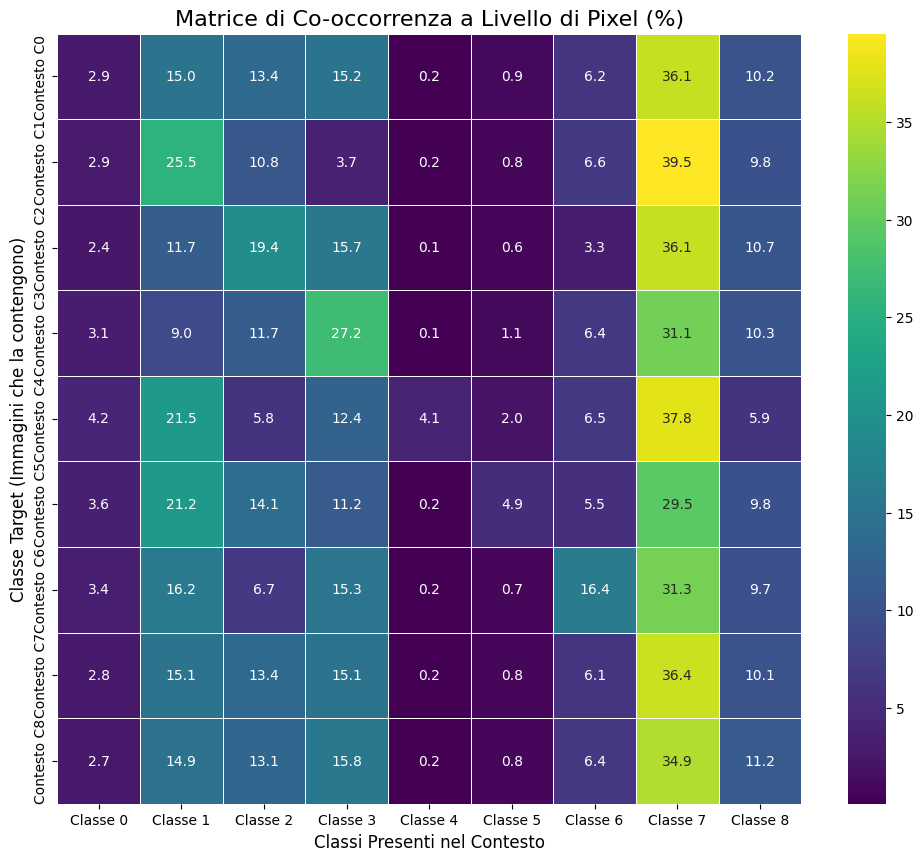

In [99]:
import numpy as np
import os
import glob
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

def analyze_class_context(dataset_path, target_class_id, num_classes=9):
    """
    Analizza il contesto di una classe target.
    (Questa funzione rimane invariata)
    """

    total_pixel_counts_in_subset = np.zeros(num_classes, dtype=np.int64)
    num_images_in_subset = 0

    all_sample_dirs = sorted(glob.glob(os.path.join(dataset_path, "*")))

    # Il desc della TQDM ora è più generico perché verrà chiamato in un ciclo
    for sample_dir in tqdm(all_sample_dirs, desc=f"Scansione (Target: {target_class_id})", leave=False):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue

        mask = np.array(Image.open(mask_path))

        unique_classes = np.unique(mask)
        if target_class_id not in unique_classes:
            continue

        num_images_in_subset += 1

        counts = np.bincount(mask.flatten(), minlength=num_classes)
        total_pixel_counts_in_subset += counts

    if num_images_in_subset == 0:
        return None, 0

    total_pixels_in_subset = total_pixel_counts_in_subset.sum()
    if total_pixels_in_subset == 0:
        return None, num_images_in_subset

    avg_distribution = (total_pixel_counts_in_subset / total_pixels_in_subset) * 100

    class_names = [f"Classe {i}" for i in range(num_classes)]
    distribution_series = pd.Series(avg_distribution, index=class_names, name=f"Contesto Classe {target_class_id}")

    return distribution_series, num_images_in_subset


# --- Esecuzione dell'Analisi Completa ---


# Iteriamo su TUTTE le classi da 0 a 8
all_classes_to_analyze = range(config["NUM_CLASSES"])
context_results_full = {}

print("--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---")
for class_id in all_classes_to_analyze:
    print(f"\nProcessing Target: Classe {class_id}")
    result, num_images = analyze_class_context(config["DATASET_PATH_TRAIN"], class_id, config["NUM_CLASSES"])
    if result is not None:
        context_results_full[f"Contesto C{class_id}"] = result
        print(f"-> Analisi per Classe {class_id} completata. Trovata in {num_images} immagini.")
    else:
        print(f"-> Classe {class_id} non trovata in nessuna immagine.")

# Creiamo un DataFrame per confrontare facilmente i risultati
if context_results_full:
    comparison_df_full = pd.DataFrame(context_results_full)

    # Per una migliore leggibilità, è meglio visualizzare la tabella trasposta
    # righe = classi target, colonne = classi presenti nel contesto
    comparison_df_transposed = comparison_df_full.transpose()

    print("\n\n--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---")
    print("Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.")
    print(comparison_df_transposed.to_string(float_format="%.2f%%"))

    # Visualizzazione con una Heatmap
    # Una heatmap è molto più efficace di un bar chart con così tanti dati
    plt.figure(figsize=(12, 10))
    # Usiamo la tabella trasposta per avere i target sull'asse Y
    sns.heatmap(
        comparison_df_transposed,
        annot=True,
        fmt=".1f", # Mostra una cifra decimale
        cmap='viridis',
        linewidths=.5
    )
    plt.title('Matrice di Co-occorrenza a Livello di Pixel (%)', fontsize=16)
    plt.xlabel('Classi Presenti nel Contesto', fontsize=12)
    plt.ylabel('Classe Target (Immagini che la contengono)', fontsize=12)
    plt.show()

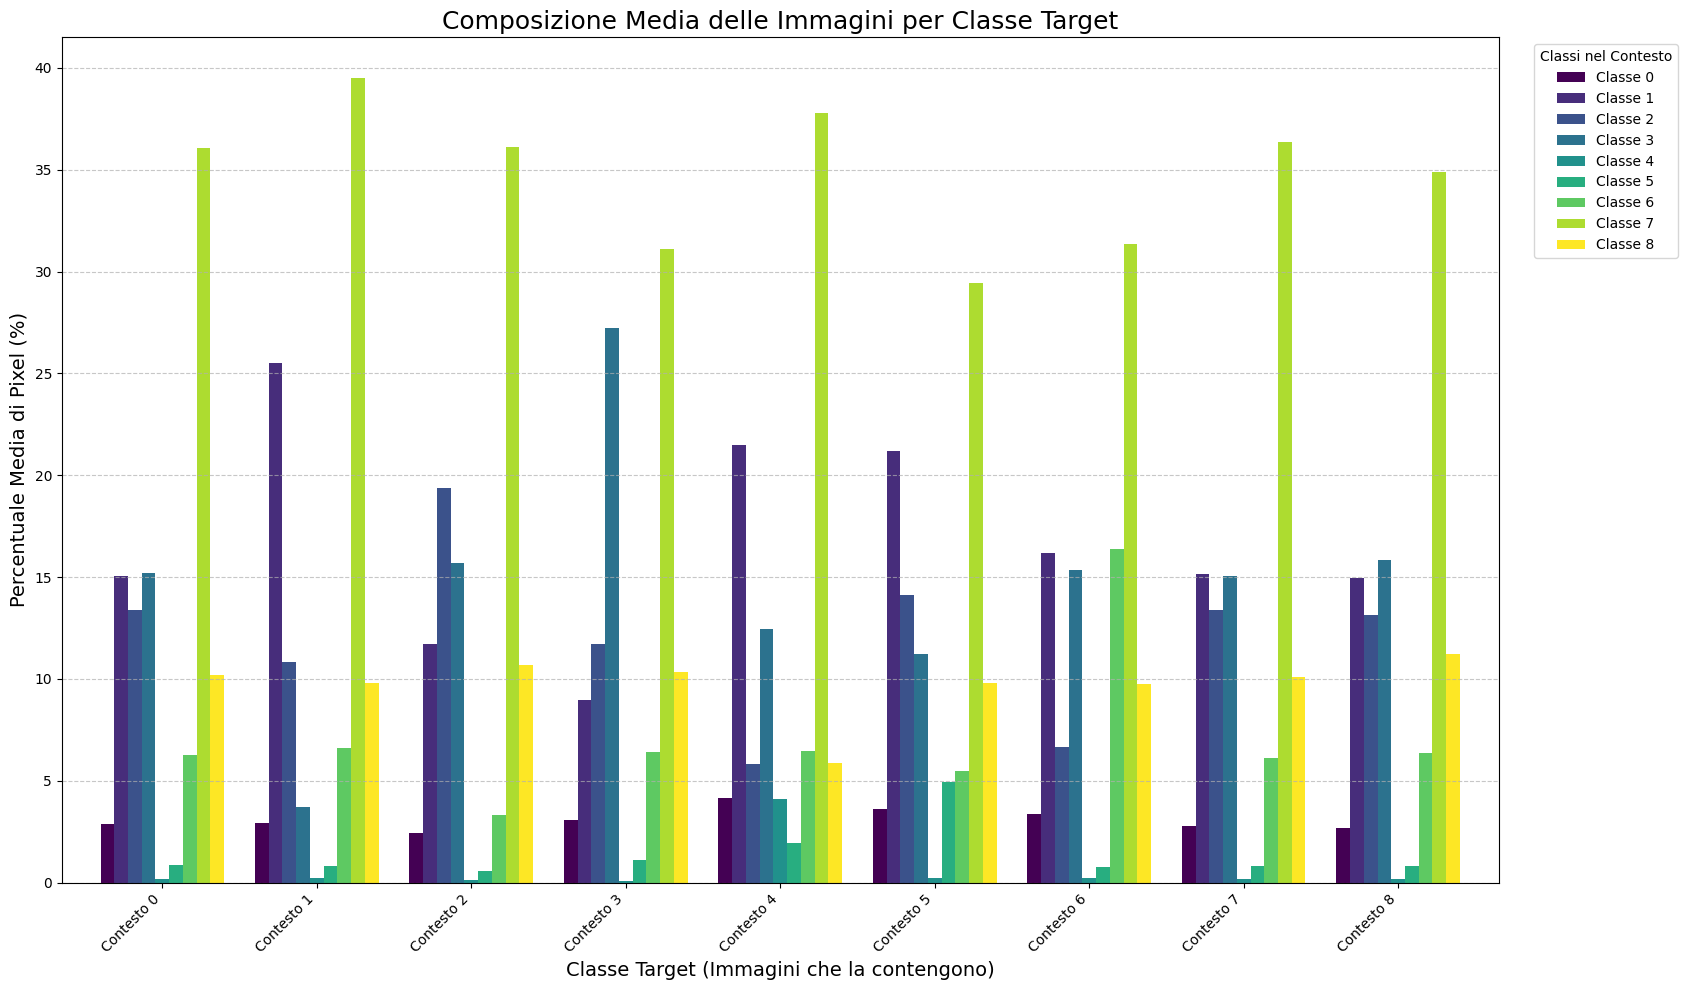

In [100]:
import matplotlib.pyplot as plt
import pandas as pd

# Assumiamo che 'comparison_df_full' sia il DataFrame che hai generato
# con l'analisi completa. Se non lo hai più in memoria, dovrai rieseguire
# la parte di analisi dello script precedente per ricalcolarlo.

# Esempio di come potrebbe essere il DataFrame (per far funzionare il codice da solo)
# Sostituisci questo con il tuo vero DataFrame se necessario
# data = {'Contesto C0': {'Classe 0': 2.9, 'Classe 1': 15.0, ...}, ...}
# comparison_df_full = pd.DataFrame(data)


# --- GENERAZIONE DEL GRAFICO A BARRE RAGGRUPPATE ---

if 'comparison_df_full' in locals() or 'comparison_df_full' in globals():
    # Trasponiamo il DataFrame per avere le classi target come gruppi sull'asse x
    # e le classi di contesto come barre individuali.
    df_for_plot = comparison_df_full.transpose()

    # Creiamo il grafico
    ax = df_for_plot.plot(
        kind='bar',
        figsize=(20, 10),
        width=0.8,
        colormap='viridis' # Usiamo lo stesso schema di colori della heatmap per coerenza
    )

    # Impostazioni per migliorare la leggibilità
    plt.title('Composizione Media delle Immagini per Classe Target', fontsize=18)
    plt.ylabel('Percentuale Media di Pixel (%)', fontsize=14)
    plt.xlabel('Classe Target (Immagini che la contengono)', fontsize=14)

    # Aggiusta le etichette dell'asse x
    # Estrae i nomi delle classi target (es. 'C0', 'C1') e li formatta
    xtick_labels = [f"Contesto {col.replace('Contesto C', '')}" for col in comparison_df_full.columns]
    ax.set_xticklabels(xtick_labels, rotation=45, ha="right")

    plt.legend(title='Classi nel Contesto', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout(rect=[0, 0, 0.85, 1]) # Aggiusta il layout per fare spazio alla leggenda

    plt.show()

else:
    print("DataFrame 'comparison_df_full' non trovato. Esegui prima l'analisi completa.")


# **Contextual Analysis**
To perform an in-depth characterization of the dataset's composition, a quantitative, pixel-level contextual analysis was conducted. The objective was to determine the average percentage distribution of classes within image subsets, where each subset is defined by the presence of a specific target class. For each class $C_i$ in the set of $N$ total classes, a data subset $D_i \subseteq D$ was constructed, containing only the images in which $C_i$ is present. Subsequently, the mean pixel frequency distribution was calculated for all classes $C_j$ (with $j \in \{0, ..., N-1\}$) within the subset $D_i$. The results were aggregated into a pixel-level co-occurrence matrix, visualized via a heatmap to facilitate the interpretation of relational patterns.

---

The analysis revealed a severe and systemic co-occurrence between the minority classes and a dominant class, identified as Class 7. The main findings are as follows:
*   Class 7 demonstrates **dominance** across the entire dataset. In images containing Class 4 (the rarest), Class 7 constitutes, on average, **37.8%** of the total pixel composition. A similar pattern is observed for Class 1, where Class 7 occupies **39.7%** of the pixels. This dominance extends to all analyzed class contexts, positioning Class 7 not only as the most frequent class but as the semantic "connective tissue" of the dataset.
*   The analysis confirms the hypothesis of a strong contextual dependency. **Minority classes (e.g., Class 1, 4, 5) do not appear in isolated or "pure" contexts but are intrinsically linked to the presence of Class 7.** This observation has critical implications for data augmentation techniques. Any instance-based oversampling strategy aimed at increasing the representation of rare classes would lead to a disproportionate and counterproductive increase in Class 7, thus exacerbating rather than mitigating the overall class imbalance.
*   Despite the dominance of Class 7, **unique contextual profiles** have emerged. For example, in the context of Class 5, Classes 2 and 3 show a higher co-occurrence than in other contexts. However, this variation is marginal compared to the overwhelming influence of Class 7.

---

The exploratory data analysis has conclusively shown that image-sampling-based **data augmentation techniques** **are insufficient** to resolve the class imbalance problem in this specific dataset.
Consequently, the development strategy must shift from data pre-processing to optimizing the model's training process. The goal is no longer to create a perfectly balanced dataset, but to equip the model with robust mechanisms to handle the inherent data imbalance.

The next step is divided into two main phases: dataset preparation and training optimization.

*   **Phase 1: Dataset Preparation and Stratified Splitting**
    The process will start with the generation of an augmented dataset using the previously developed pixel-deficit-based algorithm. This approach represents the best achievable compromise at the data level, aiming for a partial balance without drastically altering the contextual distributions. The resulting dataset, named `train_augmented`, will be combined with the original `train` dataset to form the final training **corpus**.

    To ensure an impartial and robust model evaluation, the final training corpus will be split into training and validation sets using a multi-label stratified split technique. This ensures that the proportional distribution of all classes, including the rare ones, is preserved in both subsets.

*   **Phase 2: Implementation of Imbalance-Robust Training Techniques**
    *   **Weighted Loss Function**: The core element of the training strategy will be the adoption of a weighted Cross-Entropy loss function. The weights for each class ($w_i$) will be calculated in inverse proportion to their pixel frequency ($f_i$) in the final training corpus, according to a formula that dampens extreme values, like the inverse square root of the frequency: $w_i = \frac{1}{\sqrt{f_i}}$. Applying these weights during the loss calculation will force the model to more heavily penalize classification errors on minority classes, thereby promoting the learning of discriminative features for those classes.
    *   **Granular Evaluation Metrics**: The model's performance will be monitored using the mean Intersection over Union (mIoU) as the primary metric. Additionally, the per-class IoU will be calculated and logged at the end of each training epoch on the validation set. This granular monitoring is essential to quantify the impact of the weighted loss and to verify a tangible and consistent improvement in performance on the target classes (1, 4, 5).

This methodological approach represents a standard and well-established strategy in the literature for addressing semantic segmentation problems characterized by severe class imbalance and complex contextual dependencies.

# Similarity Analysis

Calcolo degli hash percettivi per tutte le immagini...


100%|██████████| 931/931 [00:04<00:00, 222.67it/s]



Calcolo della matrice delle distanze tra gli hash...


100%|██████████| 931/931 [00:00<00:00, 1038.61it/s]



Sono state trovate 27 coppie di immagini molto simili (distanza < 5).

Esempio di coppie simili:

Coppia 1 - Distanza: 4.0
  Img 1: 0013
  Img 2: 0383


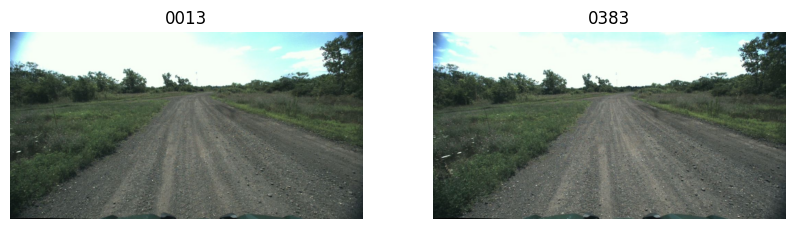


Coppia 2 - Distanza: 4.0
  Img 1: 0064
  Img 2: 0662


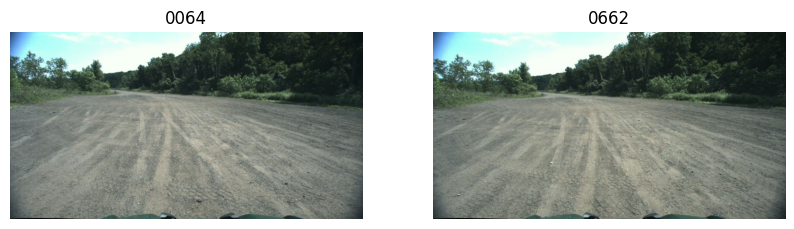


Coppia 3 - Distanza: 4.0
  Img 1: 0152
  Img 2: 1234


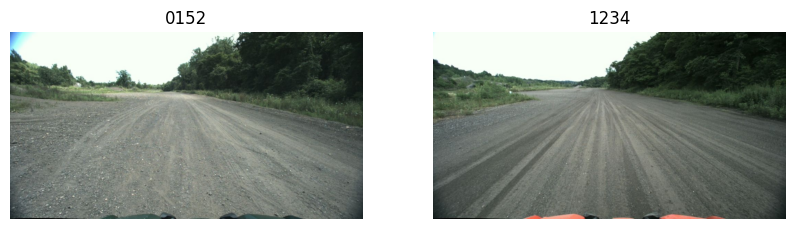


Coppia 4 - Distanza: 4.0
  Img 1: 0153
  Img 2: 0154


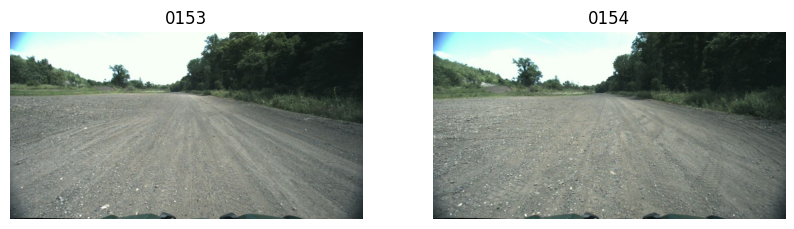

In [102]:
!pip install -q imagehash
import imagehash
from PIL import Image
import os
import glob
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt


# Calcola l'hash per ogni immagine
all_sample_dirs = sorted([d for d in glob.glob(os.path.join(config["DATASET_PATH_TRAIN"], "*")) if os.path.isdir(d) and not os.path.basename(d).startswith('__')])

hashes = {}
print("Calcolo degli hash percettivi per tutte le immagini...")
for sample_dir in tqdm(all_sample_dirs):
    img_path = os.path.join(sample_dir, 'rgb.jpg')
    try:
        with Image.open(img_path) as img:
            # pHash è robusto a piccole variazioni e cambi di dimensione
            h = imagehash.phash(img)
            hashes[sample_dir] = h
    except FileNotFoundError:
        continue

# Calcola la matrice delle distanze
# La distanza di Hamming tra due hash ci dice quanto sono diversi (0 = identici)
print("\nCalcolo della matrice delle distanze tra gli hash...")
sample_paths = list(hashes.keys())
n_samples = len(sample_paths)
distance_matrix = np.zeros((n_samples, n_samples))

for i in tqdm(range(n_samples)):
    for j in range(i, n_samples):
        dist = hashes[sample_paths[i]] - hashes[sample_paths[j]]
        distance_matrix[i, j] = dist
        distance_matrix[j, i] = dist

# Analizza i risultati
# Troviamo le coppie di immagini più simili (distanza < soglia)
SIMILARITY_THRESHOLD = 5 # Soglia sperimentale: 0 è identico, < 5 è molto simile
similar_pairs = np.where((distance_matrix > 0) & (distance_matrix < SIMILARITY_THRESHOLD))

print(f"\nSono state trovate {len(similar_pairs[0]) // 2} coppie di immagini molto simili (distanza < {SIMILARITY_THRESHOLD}).")

# Visualizziamo qualche coppia per conferma
num_pairs_to_show = 5
print("\nEsempio di coppie simili:")
for i in range(min(num_pairs_to_show, len(similar_pairs[0]))):
    idx1 = similar_pairs[0][i]
    idx2 = similar_pairs[1][i]

    # Evitiamo di stampare la stessa coppia due volte
    if idx1 >= idx2:
        continue

    path1 = sample_paths[idx1]
    path2 = sample_paths[idx2]
    dist = distance_matrix[idx1, idx2]

    print(f"\nCoppia {i+1} - Distanza: {dist}")
    print(f"  Img 1: {os.path.basename(path1)}")
    print(f"  Img 2: {os.path.basename(path2)}")

    # Visualizzazione
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(Image.open(os.path.join(path1, 'rgb.jpg')))
    axes[0].set_title(os.path.basename(path1))
    axes[0].axis('off')
    axes[1].imshow(Image.open(os.path.join(path2, 'rgb.jpg')))
    axes[1].set_title(os.path.basename(path2))
    axes[1].axis('off')
    plt.show()